In [1]:
import os, re, json, time, random, hashlib, unicodedata
from pathlib import Path
from collections import Counter, defaultdict
from enum import Enum
from typing import List, Optional

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from google import genai
from google.genai import types

load_dotenv() # на початку беремо апі ключ з енв файлу
API_KEY = os.getenv("API_KEY")
if not API_KEY:
    raise RuntimeError("no api key found")
# налаштовуємо genai клієнт
client = genai.Client(api_key=API_KEY)

LLM_MODEL = os.getenv("LLM_MODEL", "gemini-3.5-flash-lite") # модель для виведення фактів
EMBED_MODEL = "gemini-embedding-001"    # модель для ембедів
EMBED_DIM = 768
LLM_SLEEP = float(os.getenv("LLM_SLEEP", "6"))
EMBED_BATCH, EMBED_SLEEP = 50, 25.0

DATA = Path("data")
#посилання на корпус тексту, папку для кешу та виводу результатів
CORPUS, CACHE, OUT = DATA / "corpus", DATA / "cache", Path("output")
for p in (CORPUS, CACHE, OUT):
    p.mkdir(parents=True, exist_ok=True)

DOC_CLUB = {
    "Liverpool": "Liverpool", "Manchester City": "Manchester City",
    "Manchester United": "Manchester United", "PSG": "Paris Saint-Germain",
    "Arsenal": "Arsenal", "Bayern Munich": "Bayern Munich",
    "Barcelona": "FC Barcelona", "Real Madrid": "Real Madrid",
}
print("LLM:", LLM_MODEL, "| embeddings:", EMBED_MODEL, EMBED_DIM)

C:\Users\pavel\PycharmProjects\Semantic_Web_Mosiienko_lab2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LLM: gemini-3.5-flash-lite | embeddings: gemini-embedding-001 768


In [2]:
#функції які використовуються для отримання даних та поділу корпусу на чанки
def md5(s):
    return hashlib.md5(s.encode("utf-8")).hexdigest()

def call_with_retry(fn, tries=6, base=5):
    for attempt in range(tries):
        try:
            return fn()
        except Exception as e:
            msg = str(e)
            transient = any(x in msg for x in (
                "429", "500", "503", "RESOURCE_EXHAUSTED",
                "UNAVAILABLE", "DEADLINE"
            ))
            if transient and attempt < tries - 1:
                wait = base * (2 ** attempt) + random.random()
                print(f"[retry {attempt+1}/{tries-1}] Очікування {wait:.0f} с")
                time.sleep(wait)
            else:
                raise

def ask_llm(prompt, system=None, temperature=0.2):
    def run():
        return client.models.generate_content(
            model=LLM_MODEL,
            contents=prompt,
            config=types.GenerateContentConfig(
                system_instruction=system,
                temperature=temperature
            )
        )
    return (call_with_retry(run).text or "").strip()

def chunk_text(text, size=2000, overlap=200):
    units = []
    for para in text.splitlines():
        para = para.strip()
        if not para:
            continue
        if len(para) <= size:
            units.append(para)
        else:
            units.extend(x for x in re.split(r"(?<=[.!?])\s+", para) if x)

    chunks, current = [], ""
    for unit in units:
        if current and len(current) + len(unit) + 1 > size:
            chunks.append(current)
            tail = current[-overlap:] if overlap else ""
            tail = tail[tail.find(" ") + 1:] if " " in tail else tail
            current = (tail + " " + unit).strip()
        else:
            current = (current + " " + unit).strip() if current else unit
    if current:
        chunks.append(current)
    return chunks

In [3]:
#очищення тексту від зайвих структур (позиції, додаткова інформація тощо)
NOISE = [
    r"^\s*(\d+|—)\s*\t\s*(GK|DF|MF|FW)\b",
    r"^No\.\s*\tPos\.", r"^Note: Flags", r"^As of \d",
    r"^(Main articles?|See also|Further information|For information)\b",
    r"Wikimedia Commons",
    r"^\s*(Out on loan|Current squad|First-team squad|Reserves and Academy|Reserve team and Youth Academy|EDS and Academy)\s*$",
]
def clean_text(text):
    text = re.sub(r"\[(?:\d+|(?:note|nb)\s*\d+|citation needed|[a-z])\]", "", text)
    lines = [
        line.rstrip() for line in text.splitlines()
        if not any(re.search(pattern, line) for pattern in NOISE)
    ]
    return re.sub(r"\n{2,}", "\n", "\n".join(lines)).strip()

DOC_TEXT = {}
for path in sorted(CORPUS.glob("*.txt")):
    name = path.stem.replace("_", " ")
    DOC_TEXT[name] = clean_text(path.read_text(encoding="utf-8"))
# рахуємо кількість слів та символів у документах та загалом у корпусі
docs_df = pd.DataFrame([
    {"document": name, "word_count": len(text.split()), "symbols": len(text)}
    for name, text in DOC_TEXT.items()
])
display(docs_df)
print("Documents total: ", len(DOC_TEXT),", total words: ", docs_df["word_count"].sum())

,document,word_count,symbols
0,Arsenal,7436,45211
1,Barcelona,12334,74594
2,Bayern Munich,8371,51574
3,Liverpool,6174,37122
4,Manchester City,5498,33066
5,Manchester United,8353,50540
6,PSG,6368,39057
7,Real Madrid,13305,80692


Documents total:  8 , total words:  67839


In [4]:
# питання до корпусу
QUESTIONS = [
    {"id": "S1", "type": "simple",
     "q": "Хто заснував Liverpool F.C. і в якому році?",
     "gold": "John Houlding, 1892 (Liverpool.txt)"},
    {"id": "S2", "type": "simple",
     "q": "З яким рахунком PSG переміг Inter Milan у фіналі Ліги чемпіонів 2025 року?",
     "gold": "5–0, фінал у Мюнхені (PSG.txt)"},
    {"id": "S3", "type": "simple",
     "q": "Кого призначили головним тренером Liverpool через п'ять днів після звільнення Арне Слота?",
     "gold": "Andoni Iraola (Liverpool.txt)"},
    {"id": "G1", "type": "global",
     "q": "Які тренери та гравці працювали у кількох клубах корпусу і як вони пов'язують ці клуби між собою?",
     "gold": "Персони з двома або більше зв'язками з різними клубами"},
    {"id": "G2", "type": "global",
     "q": "Які суперництва між клубами корпусу описані в текстах і що їх формує?",
     "gold": "Суперництва, підтверджені документами корпусу"},
]
display(pd.DataFrame(QUESTIONS)[["id", "type", "q"]])

,id,type,q
0,S1,simple,Хто заснував Liverpool F.C. і в якому році?
1,S2,simple,З яким рахунком PSG переміг Inter Milan у фіна...
2,S3,simple,Кого призначили головним тренером Liverpool че...
3,G1,global,Які тренери та гравці працювали у кількох клуб...
4,G2,global,Які суперництва між клубами корпусу описані в ...


In [5]:
#Типи сутностей(5)
class EntityType(str, Enum):
    CLUB = "Club"
    PERSON = "Person"
    COMPETITION = "Competition"
    STADIUM = "Stadium"
    COMPANY = "Company"
#Типи зв'язків (9)
class Relation(str, Enum):
    MANAGED = "MANAGED"
    PLAYED_FOR = "PLAYED_FOR"
    WON = "WON"
    DEFEATED = "DEFEATED"
    RIVAL_OF = "RIVAL_OF"
    PLAYS_AT = "PLAYS_AT"
    OWNED_BY = "OWNED_BY"
    SPONSORED_BY = "SPONSORED_BY"
    FOUNDED_BY = "FOUNDED_BY"
#Клас факту
class Fact(BaseModel):
    subject: str
    subject_type: EntityType
    relation: Relation
    object: str
    object_type: EntityType
    year: Optional[str] = None
    evidence: str

class ExtractionResult(BaseModel):
    facts: List[Fact]
#системні налаштування для моделі
SYSTEM = (
    "Ти витягуєш факти з тексту про футбольні клуби. "
    "Використовуй лише інформацію з наданого фрагмента. Нічого не вигадуй. "
    "Назви клубів: Liverpool, Manchester City, Manchester United, Arsenal, "
    "Paris Saint-Germain, Bayern Munich, FC Barcelona, Real Madrid. "
    "Для кожного факту наведи дослівний evidence до 25 слів."
)
# функція перетворення тексту в факти
def extract_chunk(doc_name, text):
    #формуємо назву кешу
    key = md5(LLM_MODEL + SYSTEM + text)
    cache_file = CACHE / f"extract_{key}.json"
    # якщо вже існує то просто зчитаємо його
    if cache_file.exists():
        return json.loads(cache_file.read_text(encoding="utf-8")), True
    # запит до моделі разом з текстом
    prompt = (
        f"Документ: стаття про {DOC_CLUB.get(doc_name, doc_name)}. "
        "Витягни до 25 важливих фактів."
        f"--- ФРАГМЕНТ ---{text}"
    )
    # функція для відправки промту з текстом
    def run():
        return client.models.generate_content(
            model=LLM_MODEL,
            contents=prompt,
            config=types.GenerateContentConfig(
                system_instruction=SYSTEM,
                temperature=0.0,
                response_mime_type="application/json",
                response_schema=ExtractionResult
            )
        )
    # якщо не виходить з першого разу то пробуємо ще кілька разів
    response = call_with_retry(run)
    parsed = response.parsed
    if parsed is None:
        parsed = ExtractionResult.model_validate_json(response.text)

    result = [fact.model_dump(mode="json") for fact in parsed.facts]
    cache_file.write_text(
        json.dumps(result, ensure_ascii=False), encoding="utf-8"
    )
    return result, False

In [6]:
# поділ корпусу на чанки по 6000 слів та виведення фактів з чанків завдяки gemini 3.5 lite
raw_facts = []
jobs = [
    (name, i, chunk)
    for name, text in DOC_TEXT.items()
    for i, chunk in enumerate(chunk_text(text, size=6000, overlap=0))
]
print("Total chunks:", len(jobs))

for name, index, chunk in tqdm(jobs):
    extracted, cached = extract_chunk(name, chunk)
    for fact in extracted:
        fact["source"] = name
        fact["chunk"] = index
    raw_facts.extend(extracted)
    if not cached:
        time.sleep(LLM_SLEEP)

print("Raw facts:", len(raw_facts))

Total chunks: 77


100%|██████████| 77/77 [00:00<00:00, 140.24it/s]

Raw facts: 478


In [7]:
# Очищення фактів від дублікатів та несумісних даних
ALIASES = {
    "man city": "Manchester City",
    "manchester city fc": "Manchester City",
    "man utd": "Manchester United",
    "man united": "Manchester United",
    "Tottenham": "Tottenham Hotspur",
    "manchester united fc": "Manchester United",
    "psg": "Paris Saint-Germain",
    "paris sg": "Paris Saint-Germain",
    "paris saint germain": "Paris Saint-Germain",
    "bayern": "Bayern Munich",
    "bayern münchen": "Bayern Munich",
    "fc bayern munich": "Bayern Munich",
    "barcelona": "FC Barcelona",
    "barça": "FC Barcelona",
    "futbol club barcelona": "FC Barcelona",
    "real madrid cf": "Real Madrid",
    "liverpool fc": "Liverpool",
    "arsenal fc": "Arsenal",
    "european cup": "UEFA Champions League",
    "champions league": "UEFA Champions League",
    "english premier league": "Premier League",
    "josep guardiola": "Pep Guardiola",
    "sir alex ferguson": "Alex Ferguson",
}

def apply_aliases(name):
    value = re.sub(r"\s+", " ", name).strip().strip('"\\"')
    return ALIASES.get(value.lower(), value)

def norm_key(name):
    value = unicodedata.normalize("NFKD", name)
    value = value.encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", value)

for fact in raw_facts:
    fact["subject"] = apply_aliases(fact["subject"])
    fact["object"] = apply_aliases(fact["object"])

frequency = Counter(
    name for fact in raw_facts
    for name in (fact["subject"], fact["object"])
)
groups = defaultdict(list)
for name in frequency:
    groups[norm_key(name)].append(name)

merge = {
    name: max(names, key=lambda x: frequency[x])
    for names in groups.values() for name in names
}
for fact in raw_facts:
    fact["subject"] = merge[fact["subject"]]
    fact["object"] = merge[fact["object"]]

type_votes = defaultdict(Counter)
for fact in raw_facts:
    type_votes[fact["subject"]][fact["subject_type"]] += 1
    type_votes[fact["object"]][fact["object_type"]] += 1

ENTITY_TYPE = {
    name: votes.most_common(1)[0][0]
    for name, votes in type_votes.items()
}

ALLOWED = {
    "MANAGED": ({"Person"}, {"Club"}),
    "PLAYED_FOR": ({"Person"}, {"Club"}),
    "WON": ({"Club", "Person"}, {"Competition"}),
    "DEFEATED": ({"Club"}, {"Club"}),
    "RIVAL_OF": ({"Club"}, {"Club"}),
    "PLAYS_AT": ({"Club"}, {"Stadium"}),
    "OWNED_BY": ({"Club"}, {"Person", "Company"}),
    "SPONSORED_BY": ({"Club"}, {"Company"}),
    "FOUNDED_BY": ({"Club"}, {"Person", "Company"}),
}

facts, dropped, seen = [], Counter(), set()
for fact in raw_facts:
    subject, obj, relation = (
        fact["subject"], fact["object"], fact["relation"]
    )
    st, ot = ENTITY_TYPE[subject], ENTITY_TYPE[obj]

    if subject == obj:
        dropped["subject == object"] += 1
        continue
    if st not in ALLOWED[relation][0] or ot not in ALLOWED[relation][1]:
        dropped["несумісні типи зв'язку"] += 1
        continue

    key = (subject, relation, obj, fact.get("year"))
    if key in seen:
        dropped["дублікат"] += 1
        continue
    seen.add(key)

    facts.append({
        "id": len(facts),
        "subject": subject, "subject_type": st,
        "relation": relation,
        "object": obj, "object_type": ot,
        "year": fact.get("year"),
        "evidence": fact["evidence"],
        "source": fact["source"], "chunk": fact["chunk"]
    })

(DATA / "facts.json").write_text(
    json.dumps(facts, ensure_ascii=False, indent=1), encoding="utf-8"
)

print(f"Фактів після очищення: {len(facts)} (сирих: {len(raw_facts)})")
print("Відкинуто:", dict(dropped))
print(pd.Series(Counter(f["relation"] for f in facts)))
assert len(facts) >= 30, "Потрібно щонайменше 30 фактів"
display(pd.DataFrame(facts).head(10))

Фактів після очищення: 385 (сирих: 478)
Відкинуто: {"несумісні типи зв'язку": 46, 'дублікат': 46, 'subject == object': 1}
WON             135
PLAYS_AT         17
MANAGED          83
RIVAL_OF         26
DEFEATED         65
SPONSORED_BY     20
PLAYED_FOR       37
OWNED_BY          2
dtype: int64


,id,subject,subject_type,relation,object,object_type,year,evidence,source,chunk
0,0,Arsenal,Club,WON,Premier League,Competition,NaN,"They compete in the Premier League, the top ti...",Arsenal,0
1,1,Arsenal,Club,PLAYS_AT,Arsenal Stadium,Stadium,1913,"In 1913, the club crossed the city to the Arse...",Arsenal,0
2,2,Arsenal,Club,PLAYS_AT,Emirates Stadium,Stadium,2006,"In 2006, the club moved to the nearby Emirates...",Arsenal,0
3,3,Herbert Chapman,Person,MANAGED,Arsenal,Club,NaN,Herbert Chapman won the club its first silverw...,Arsenal,0
4,4,Arsène Wenger,Person,MANAGED,Arsenal,Club,NaN,Arsène Wenger was the club's longest-serving m...,Arsenal,0
5,5,Arsenal,Club,RIVAL_OF,Tottenham Hotspur,Club,1913,becoming close neighbours of Tottenham Hotspur...,Arsenal,0
6,6,Herbert Chapman,Person,MANAGED,Arsenal,Club,1925,Arsenal's location and record-breaking salary ...,Arsenal,1
7,7,Tom Whittaker,Person,MANAGED,Arsenal,Club,NaN,Tom Whittaker who would one day rise to become...,Arsenal,1
8,8,Arsenal,Club,WON,FA Cup,Competition,1930,Chapman's Arsenal claimed their first national...,Arsenal,1
9,9,Joe Shaw,Person,MANAGED,Arsenal,Club,NaN,Chapman's death meant work was left to his col...,Arsenal,1


In [8]:

def normalize_spaces(text):
    return re.sub(r"\s+", " ", text).strip().lower()
# функця для отримання контексту що підтверджує факти
def find_context(source, evidence, width=220):
    text = normalize_spaces(DOC_TEXT[source])
    ev = normalize_spaces(evidence)
    if not ev:
        return ""
    index = text.find(ev[:60])
    return text[max(0, index-width):index+len(ev)+width] if index >= 0 else ""

found = [
    bool(find_context(f["source"], f["evidence"], 0))
    for f in facts
]
print(f"Evidence знайдено: {sum(found)}/{len(found)} ({np.mean(found):.1%})")

sample = random.Random(42).sample(facts, min(20, len(facts)))
rows = []
for fact in sample:
    rows.append({
        "id": fact["id"],
        "source": fact["source"],
        "fact": f'{fact["subject"]} --{fact["relation"]}--> {fact["object"]} ({fact["year"]})',
        "evidence": fact["evidence"],
        "context_in_source": find_context(
            fact["source"], fact["evidence"]
        ) or "НЕ ЗНАЙДЕНО",
        "correct": "",
        "error_type": ""
    })
# формування вибірки з мінімум 20 фактів на ручну перевірку
pd.DataFrame(rows).to_csv(
    OUT / "verification.csv", index=False, encoding="utf-8-sig"
)

print("Створено output/verification.csv")

Evidence знайдено: 367/385 (95.3%)
Створено output/verification.csv


In [28]:
#виведення результатів ручної верифікації
verification = pd.read_csv(OUT / "verification.csv")
verification["correct"] = pd.to_numeric(
    verification["correct"], errors="coerce"
)
if verification["correct"].isna().any():
    print("Заповніть усі значення correct у output/verification.csv")
else:
    accuracy = verification["correct"].mean()
    print(f"Коректних фактів: {int(verification['correct'].sum())}/"
          f"{len(verification)} = {accuracy:.1%}")
    print(verification.loc[
        verification["correct"] == 0, "error_type"
    ].value_counts())

Заповніть усі значення correct у output/verification.csv


In [9]:
#повторне чанкування для ембедингу для векторного пошуку
chunks = []
for name, text in DOC_TEXT.items():
    for i, chunk in enumerate(chunk_text(text, size=2000, overlap=200)):
        if len(chunk) >= 150:
            chunks.append({
                "id": f"{name}#{i}", "doc": name, "text": chunk
            })

print("Чанків:", len(chunks))

def embed(texts, task):
    vectors = []
    for i in range(0, len(texts), EMBED_BATCH):
        batch = texts[i:i+EMBED_BATCH]
        response = call_with_retry(lambda: client.models.embed_content(
            model=EMBED_MODEL,
            contents=batch,
            config=types.EmbedContentConfig(
                task_type=task,
                output_dimensionality=EMBED_DIM
            )
        ))
        vectors.extend(item.values for item in response.embeddings)
        if i + EMBED_BATCH < len(texts):
            time.sleep(EMBED_SLEEP)

    array = np.asarray(vectors, dtype="float32")
    return array / np.linalg.norm(array, axis=1, keepdims=True)

embed_inputs = [
    f"Club: {DOC_CLUB.get(c['doc'], c['doc'])}\\n{c['text']}"
    for c in chunks
]
embedding_cache = CACHE / (
    f"embeddings_{md5(EMBED_MODEL + str(EMBED_DIM) + ''.join(embed_inputs))}.npy"
)

if embedding_cache.exists():
    E = np.load(embedding_cache)
else:
    E = embed(embed_inputs, "RETRIEVAL_DOCUMENT")
    np.save(embedding_cache, E)

print("Матриця ембедингів:", E.shape)

Чанків: 290
Матриця ембедингів: (290, 768)


In [10]:
#налаштування хромадб для векторного пошуку
import chromadb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

chroma = chromadb.PersistentClient(path=str(DATA / "chroma"))
try:
    chroma.delete_collection("football")
except Exception:
    pass

collection = chroma.create_collection(
    "football", metadata={"hnsw:space": "cosine"}
)
collection.add(
    ids=[c["id"] for c in chunks],
    embeddings=E.tolist(),
    documents=[c["text"] for c in chunks],
    metadatas=[{"doc": c["doc"]} for c in chunks]
)
# функція для векторного пошуку через колекцію в хромадб
def vector_search(query, n=5):
    q = embed([query], "RETRIEVAL_QUERY")
    result = collection.query(
        query_embeddings=q.tolist(), n_results=n
    )
    return [
        {"id": i, "doc": m["doc"], "score": 1-d, "text": t}
        for i, m, d, t in zip(
            result["ids"][0], result["metadatas"][0],
            result["distances"][0], result["documents"][0]
        )
    ]

tfidf = TfidfVectorizer(
    lowercase=True, stop_words="english",
    ngram_range=(1, 2), sublinear_tf=True
)
X = tfidf.fit_transform([c["text"] for c in chunks])
# функція для повнотекстового пошуку
def keyword_search(query, n=5):
    scores = cosine_similarity(tfidf.transform([query]), X).ravel()
    indexes = scores.argsort()[::-1][:n]
    return [
        {"id": chunks[i]["id"], "doc": chunks[i]["doc"],
         "score": float(scores[i]), "text": chunks[i]["text"]}
        for i in indexes if scores[i] > 0
    ]

def show_results(results, k=3):
    for item in results[:k]:
        print(f'{item["doc"]:<20} {item["score"]:.3f}  '
              f'{item["text"][:120].replace(chr(10), " ")}...')

print("Пошук готовий.")

Пошук готовий.


In [11]:
# тестова вибірка питань для перевірки роботи обох методів пошуку
TESTS = [
    ("At which club did supporters die at a semi-final because police lost control of the crowd?", "Liverpool", "перефраз"),
    ("Which side went a whole top-flight season undefeated and earned a famous nickname?", "Arsenal", "перефраз"),
    ("Which club bought a Brazilian winger from Real Madrid for a British record fee?", "Manchester City", "перефраз"),
    ("Rune Hauge", "Arsenal", "точне ім'я"),
    ("£218.9 million", "Liverpool", "число"),
    ("Estádio do Dragão", "Manchester City", "назва"),
]

summary = []
for query, expected, kind in TESTS:
    keyword = keyword_search(query, 3)
    vector = vector_search(query, 3)
    summary.append({
        "запит": query,
        "тип": kind,
        "очікується": expected,
        "keyword top-1": keyword[0]["doc"] if keyword else "-",
        "keyword hit@3": expected in [x["doc"] for x in keyword],
        "vector top-1": vector[0]["doc"] if vector else "-",
        "vector hit@3": expected in [x["doc"] for x in vector]
    })
    time.sleep(1)

display(pd.DataFrame(summary))

,запит,тип,очікується,keyword top-1,keyword hit@3,vector top-1,vector hit@3
0,At which club did supporters die at a semi-fin...,перефраз,Liverpool,Liverpool,True,Liverpool,True
1,Which side went a whole top-flight season unde...,перефраз,Arsenal,Liverpool,True,Arsenal,True
2,Which club bought a Brazilian winger from Real...,перефраз,Manchester City,Manchester City,True,Manchester City,True
3,Rune Hauge,точне ім'я,Arsenal,Arsenal,True,Manchester United,False
4,£218.9 million,число,Liverpool,Liverpool,True,Manchester United,True
5,Estádio do Dragão,назва,Manchester City,Manchester City,True,PSG,False


In [12]:
#побудова GraphRag графа з фактів
import networkx as nx
import community as community_louvain
import matplotlib.pyplot as plt

facts = json.loads((DATA / "facts.json").read_text(encoding="utf-8"))
G = nx.MultiDiGraph()

for fact in facts:
    G.add_node(fact["subject"], type=fact["subject_type"])
    G.add_node(fact["object"], type=fact["object_type"])
    G.add_edge(
        fact["subject"], fact["object"],
        relation=fact["relation"], year=fact["year"],
        source=fact["source"]
    )

UG = nx.Graph()
UG.add_nodes_from(G.nodes(data=True))
for u, v in G.edges():
    if UG.has_edge(u, v):
        UG[u][v]["weight"] += 1
    else:
        UG.add_edge(u, v, weight=1)

print("Вузлів:", G.number_of_nodes())
print("Ребер:", G.number_of_edges())
print("Компонент зв'язності:", nx.number_connected_components(UG))

Вузлів: 191
Ребер: 385
Компонент зв'язності: 1


C:\Users\pavel\AppData\Local\Temp\ipykernel_5156\3319683090.py:29: UserWarning: Glyph 129 (\x81) missing from font(s) DejaVu Sans.
  plt.savefig(OUT / "graph.png", dpi=150, bbox_inches="tight")
C:\Users\pavel\PycharmProjects\Semantic_Web_Mosiienko_lab2\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 129 (\x81) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


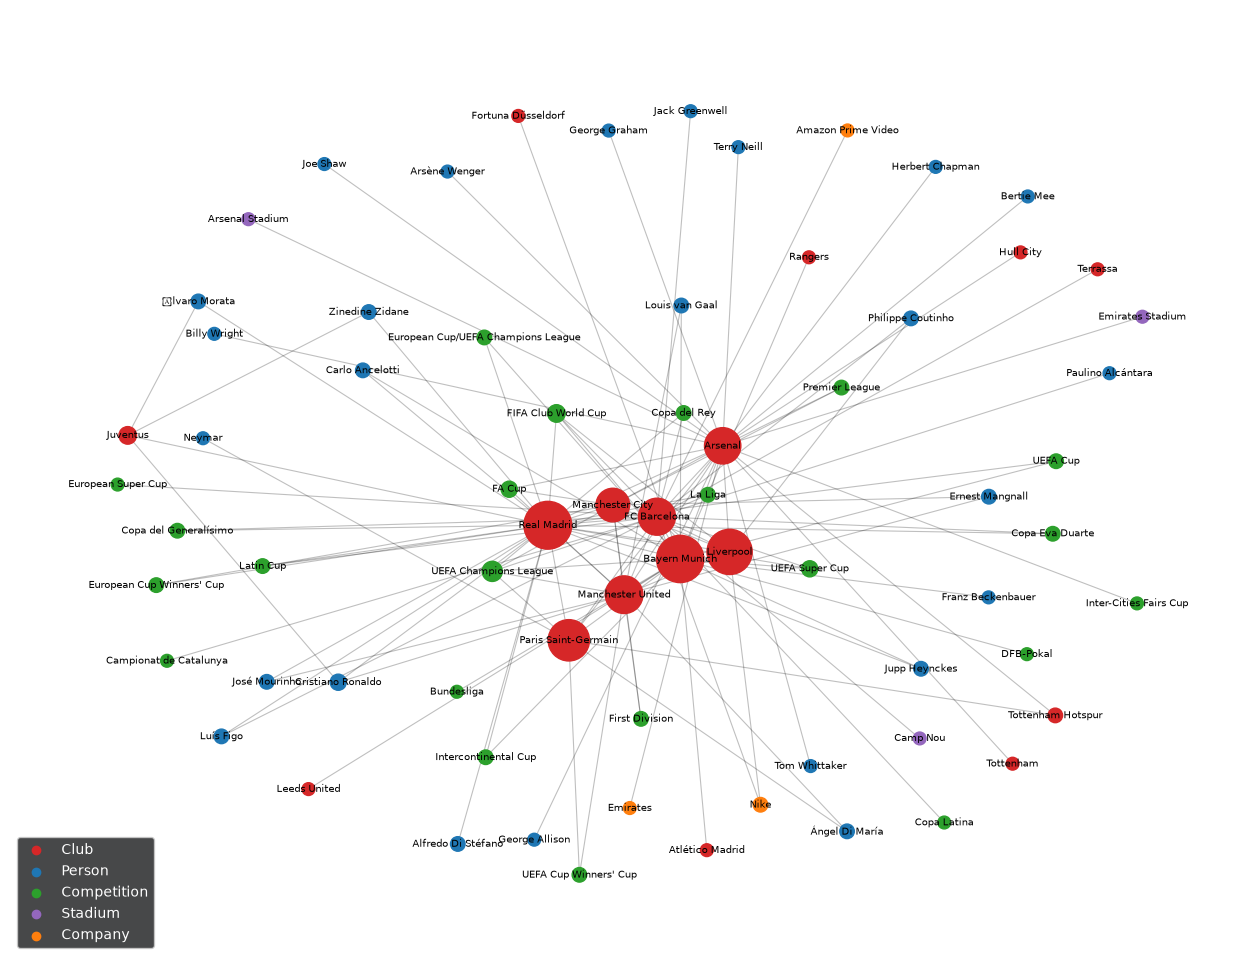

Збережено output/graph.png


In [13]:
COLORS = {
    "Club": "#d62728", "Person": "#1f77b4",
    "Competition": "#2ca02c", "Stadium": "#9467bd",
    "Company": "#ff7f0e"
}

top_nodes = [
    node for node, degree in
    sorted(UG.degree, key=lambda x: -x[1])[:70]
]
H = UG.subgraph(top_nodes)

plt.figure(figsize=(16, 12))
pos = nx.spring_layout(H, seed=42, k=0.9)
nx.draw_networkx_edges(H, pos, alpha=0.25, width=0.8)
nx.draw_networkx_nodes(
    H, pos,
    node_color=[COLORS[UG.nodes[n]["type"]] for n in H],
    node_size=[60 + 25 * UG.degree(n) for n in H]
)
nx.draw_networkx_labels(H, pos, font_size=7)
for entity_type, color in COLORS.items():
    plt.scatter([], [], c=color, label=entity_type)
plt.legend(loc="lower left")
plt.axis("off")
plt.title("Граф знань — топ-70 вузлів за ступенем")
fig = plt.gcf()
fig.patch.set_facecolor("white")
plt.savefig(OUT / "graph.png", dpi=150, bbox_inches="tight")
plt.show()
print("Збережено output/graph.png")

In [14]:
#формування спільнот з використанням louvain
partition = community_louvain.best_partition(
    UG, weight="weight", random_state=42
)
communities = defaultdict(list)
for node, community_id in partition.items():
    communities[community_id].append(node)

ranked = sorted(
    communities.items(), key=lambda item: -len(item[1])
)
print(
    f"Спільнот: {len(ranked)} | modularity: "
    f"{community_louvain.modularity(partition, UG, weight='weight'):.3f}"
)
for community_id, nodes in ranked[:12]:
    hubs = sorted(nodes, key=lambda n: -UG.degree(n))[:6]
    print(
        f"Спільнота {community_id}: {len(nodes)} вузлів; "
        f"хаби: {', '.join(hubs)}"
    )

Спільнот: 7 | modularity: 0.570
Спільнота 4: 42 вузлів; хаби: Real Madrid, FC Barcelona, UEFA Champions League, Juventus, UEFA Super Cup, Cristiano Ronaldo
Спільнота 6: 36 вузлів; хаби: Bayern Munich, FIFA Club World Cup, Intercontinental Cup, UEFA Cup, Jupp Heynckes, Carlo Ancelotti
Спільнота 3: 34 вузлів; хаби: Liverpool, Philippe Coutinho, Anfield, Bill Shankly, Bob Paisley, Joe Fagan
Спільнота 1: 32 вузлів; хаби: Manchester United, Manchester City, FA Cup, Premier League, Louis van Gaal, European Cup Winners' Cup
Спільнота 5: 28 вузлів; хаби: Paris Saint-Germain, UEFA Cup Winners' Cup, Ángel Di María, Neymar, Parc des Princes, Qatar Sports Investments
Спільнота 0: 17 вузлів; хаби: Arsenal, Tottenham Hotspur, Arsenal Stadium, Emirates Stadium, Herbert Chapman, Arsène Wenger
Спільнота 2: 2 вузлів; хаби: Alfredo Di Stéfano, European Cups


In [15]:
MIN_COMM, MAX_COMM, MAX_FACTS = 4, 20, 60

def community_facts(nodes):
    node_set = set(nodes)
    rows = []
    for u, v, data in G.edges(data=True):
        if u in node_set and v in node_set:
            rows.append((
                u, data["relation"], v,
                data.get("year"), data.get("source")
            ))
    rows = list(dict.fromkeys(rows))
    rows.sort(
        key=lambda row: -(UG.degree(row[0]) + UG.degree(row[2]))
    )
    return rows[:MAX_FACTS]

def summarize_community(community_id, nodes):
    rows = community_facts(nodes)
    links = "\\n".join(
        f"- {u} ({UG.nodes[u]['type']}) --{rel}--> "
        f"{v} ({UG.nodes[v]['type']}), рік: {year or '?'} [{source}]"
        for u, rel, v, year, source in rows
    )
    prompt = (
        "Напиши українською огляд спільноти графа знань (4–6 речень). "
        "Поясни, яка тема об'єднує сутності та які клуби й персони пов'язані. "
        "Використовуй лише наведені дані. Нічого не вигадуй.\\n\\n"
        f"Сутності: {', '.join(nodes[:40])}\\n\\nЗв'язки:\\n{links}"
    )

    key = md5(LLM_MODEL + prompt)
    cache_file = CACHE / f"commsum_{key}.txt"
    if cache_file.exists():
        return cache_file.read_text(encoding="utf-8"), True

    result = ask_llm(prompt)
    cache_file.write_text(result, encoding="utf-8")
    return result, False

community_summaries = {}
selected = [
    (cid, nodes) for cid, nodes in ranked
    if len(nodes) >= MIN_COMM
][:MAX_COMM]

for cid, nodes in tqdm(selected):
    text, cached = summarize_community(cid, nodes)
    community_summaries[cid] = text
    if not cached:
        time.sleep(LLM_SLEEP)

(OUT / "community_summaries.json").write_text(
    json.dumps(community_summaries, ensure_ascii=False, indent=1),
    encoding="utf-8"
)
print("Резюме спільнот:", len(community_summaries))

100%|██████████| 6/6 [00:00<00:00, 136.30it/s]

Резюме спільнот: 6


In [17]:
def graphrag_answer(question):
    blocks = "\\n\\n".join(
        f"[Спільнота {cid}]\\n{text}"
        for cid, text in community_summaries.items()
    )
    prompt = (
        f"Запитання: {question}\\n\\n"
        "Дай повну відповідь українською на основі резюме спільнот. "
        "Називай конкретних людей, клуби та зв'язки. "
        "Якщо даних недостатньо, скажи про це.\\n\\n" + blocks
    )
    return ask_llm(prompt)

def vector_rag_answer(question, n=8):
    hits = vector_search(question, n)
    context = "\\n\\n".join(
        f'[{hit["doc"]}]\\n{hit["text"]}' for hit in hits
    )
    prompt = (
        f"Запитання: {question}\\n\\n"
        "Дай відповідь українською лише на основі наведених фрагментів. "
        "Якщо даних недостатньо, прямо скажи про це.\\n\\n" + context
    )
    return ask_llm(prompt), hits

global_question = next(
    item["q"] for item in QUESTIONS if item["id"] == "G2"
)

print("Запитання:", global_question)
answer_graph = graphrag_answer(global_question)
time.sleep(LLM_SLEEP)
answer_vector, vector_hits = vector_rag_answer(global_question)

(OUT / "answer_graphrag.txt").write_text(
    answer_graph, encoding="utf-8"
)
(OUT / "answer_vector_rag.txt").write_text(
    answer_vector, encoding="utf-8"
)

print("\\n===== GraphRAG =====\\n", answer_graph)
print("\\n===== vector-RAG =====\\n", answer_vector)
print("Документи vector-RAG:", Counter(x["doc"] for x in vector_hits))

Запитання: Які суперництва між клубами корпусу описані в текстах і що їх формує?
\n===== GraphRAG =====\n На основі наданих текстів (резюме спільнот) нижче наведено повну інформацію про описані суперництва між футбольними клубами, а також чинники, що їх формують.

### 1. Описані суперництва та зв'язки між клубами

* **Real Madrid та FC Barcelona (Спільнота 4):**
  * Між цими клубами зафіксовані прямі суперництва та матчі.
  * *Формування:* Вони є головними клубами спільноти, чиї стосунки та історія будуються навколо спортивних змагань, трофеїв, стадіонів та виступів всесвітньо відомих гравців і тренерів (зокрема, Cristiano Ronaldo, Luís Figo, Zinedine Zidane). У текстах також згадуються інші клуби (Juventus та Partizan Belgrade), проте конкретні суперництва з ними не описані.

* **Bayern Munich та інші клуби (Спільнота 6):**
  * Клуб «Bayern Munich» має протистояння з іншими футбольними колективами.
  * *Формування:* Суперництво формується через виступи мюнхенської команди на домашніх 

In [19]:
rival_pairs = {
    frozenset((f["subject"], f["object"]))
    for f in facts if f["relation"] == "RIVAL_OF"
}

print("Пари клубів-суперників:")
for p in sorted(rival_pairs, key=lambda p: sorted(p)):
    print("  ", " — ".join(sorted(p)))

SHORT = {
    "FC Barcelona": ["barcelona", "barça", "барселон"],
    "Paris Saint-Germain": ["psg", "paris saint-germain", "псж"],
    "Manchester United": ["manchester united", "man united", "манчестер юнайтед"],
    "Manchester City": ["manchester city", "man city", "манчестер сіті"],
    "Real Madrid": ["real madrid", "реал"],
    "Bayern Munich": ["bayern", "баварі"],
    "Liverpool": ["liverpool", "ліверпул"],
    "Arsenal": ["arsenal", "арсенал"],
}

def variants(name):
    return SHORT.get(name, [name.lower()])

def pairs_mentioned(answer):
    found = set()
    for part in re.split(r"\n+", answer.lower()):
        for p in rival_pairs:
            a, b = tuple(p)
            if any(v in part for v in variants(a)) and any(v in part for v in variants(b)):
                found.add(p)
    return list(found)

comparison = pd.DataFrame([
    {"метод": "GraphRAG", "слів": len(answer_graph.split()),
     "пар-суперників названо": len(pairs_mentioned(answer_graph)),
     "всього пар": len(rival_pairs)},
    {"метод": "vector-RAG", "слів": len(answer_vector.split()),
     "пар-суперників названо": len(pairs_mentioned(answer_vector)),
     "всього пар": len(rival_pairs)},
])
display(comparison)

Пари клубів-суперників:
   Arsenal — Liverpool
   Arsenal — Manchester United
   Arsenal — Tottenham
   Arsenal — Tottenham Hotspur
   Bayern Munich — Borussia Dortmund
   Bayern Munich — FC Barcelona
   Bayern Munich — Manchester United
   Bayern Munich — Real Madrid
   Everton — Liverpool
   FC Barcelona — Liverpool
   FC Barcelona — Real Madrid
   Liverpool — Manchester City
   Liverpool — Manchester United
   Liverpool — Real Madrid
   Manchester City — Manchester United
   Manchester United — Real Madrid
   Paris FC — Paris Saint-Germain


,метод,слів,пар-суперників названо,всього пар
0,GraphRAG,511,7,17
1,vector-RAG,443,9,17
